---
title: "2.6 Área de estudio y exposición base"
short_title: "2.6 Área de estudio (cuaderno)"
subtitle: "Límite municipal, área urbana, malla de análisis, edificaciones, población y coberturas"
description: "Cuaderno que construye las capas base de exposición usadas por todos los análisis de Leticia."
keywords: [Leticia, exposición, edificaciones, población, Sentinel-2, malla]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/02_datos/26_area_estudio.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

Este cuaderno construye las **capas base** que reutilizan todos los análisis de la Sección 3: el límite
municipal, el área urbana de análisis, la malla de celdas de 200 m, las edificaciones con su población
estimada, un mosaico satelital como mapa base, el modelo de superficie y las coberturas del suelo.
Cada capa se descarga una sola vez y queda guardada en `data/processed/`.

:::{note} Qué es «Leticia» en este libro
El análisis urbano cubre la **cabecera municipal y su periferia** sobre la vía a Tarapacá, recortada por el
límite municipal del DANE. Tabatinga (Brasil), conurbada con Leticia, aparece en los mapas como contexto pero
no entra en los conteos. El entorno regional (río, islas, bosques) se usa en los análisis de dinámica fluvial
e incendios.
:::

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import aoi, espacial, exposicion, fuentes, viz
from leticia.config import aoi_cfg

cfg = aoi_cfg()
mun = fuentes.limite_municipal()
urbana = aoi.area_urbana()
display(pd.Series({
    "Municipio": f"{cfg['municipio']} ({cfg['departamento']}), DIVIPOLA {cfg['codigo_divipola']}",
    "Área municipal (km²)": round(float(mun.to_crs(cfg['crs_trabajo']).area.iloc[0] / 1e6), 1),
    "Área urbana de análisis (km²)": round(float(urbana.area.iloc[0] / 1e6), 1),
    "CRS de trabajo": cfg["crs_trabajo"],
}, name="valor").to_frame())

,valor
Municipio,"Leticia (Amazonas), DIVIPOLA 91001"
Área municipal (km²),"6,158.70"
Área urbana de análisis (km²),38.70
CRS de trabajo,EPSG:9377


## 1. Localización

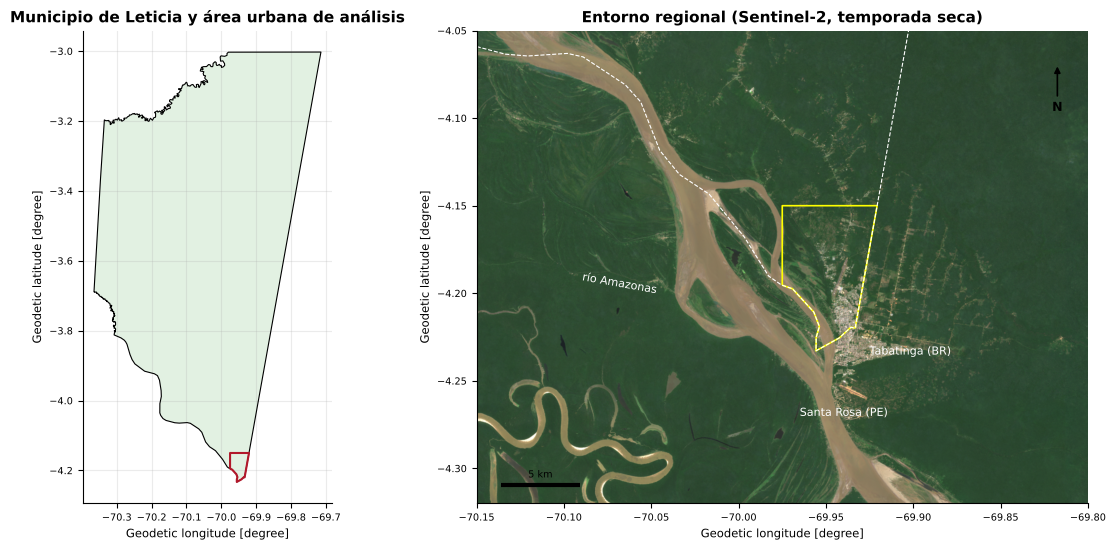

In [3]:
rgb = espacial.mosaico_rgb()
fig, ax = plt.subplots(1, 2, figsize=(12, 5.6), gridspec_kw={"width_ratios": [1, 1.25]})
mun.boundary.plot(ax=ax[0], color="k", lw=0.8)
mun.plot(ax=ax[0], color="#cfe8cf", alpha=0.6)
urbana.to_crs(4326).boundary.plot(ax=ax[0], color=viz.ROJO, lw=1.5)
ax[0].set_title("Municipio de Leticia y área urbana de análisis")
ax[0].tick_params(labelsize=7)
viz.fondo(ax[1], "bbox_regional")
urbana.to_crs(4326).boundary.plot(ax=ax[1], color="yellow", lw=1.2)
mun.boundary.plot(ax=ax[1], color="white", lw=0.8, ls="--")
viz.marco(ax[1], "bbox_regional", "Entorno regional (Sentinel-2, temporada seca)")
ax[1].annotate("Tabatinga (BR)", (-69.925, -4.235), color="white", fontsize=8)
ax[1].annotate("Santa Rosa (PE)", (-69.965, -4.27), color="white", fontsize=8)
ax[1].annotate("río Amazonas", (-70.09, -4.20), color="white", fontsize=8, rotation=-10)
fig.tight_layout()

In [4]:
viz.pie(viz.nota_fuente("limite_municipal", "sentinel2"))

*Fuente: DANE (vía geoBoundaries) — Marco Geoestadístico Nacional, nivel municipal (2020); ESA Copernicus (Microsoft Planetary Computer) — Sentinel-2 L2A.*

**Lectura.** Leticia ocupa una terraza sobre la margen izquierda del Amazonas, en la triple frontera con
Tabatinga (Brasil) y Santa Rosa (Perú). Frente a la ciudad el río se divide en brazos separados por islas
(Santa Rosa, Rondiña y la isla de la Fantasía), cuya forma cambia con cada creciente: es la dinámica que se
analiza en [3.3](../03_analisis/33_erosion/index.md).

## 2. Edificaciones y población

In [5]:
edif = exposicion.edificaciones_urbanas()
malla = exposicion.malla_exposicion()
display(exposicion.resumen(malla).round(0).astype(int).to_frame("valor"))

,valor
celdas,1040
celdas con edificaciones,404
edificaciones,6808
área construida (ha),127
población estimada,46507


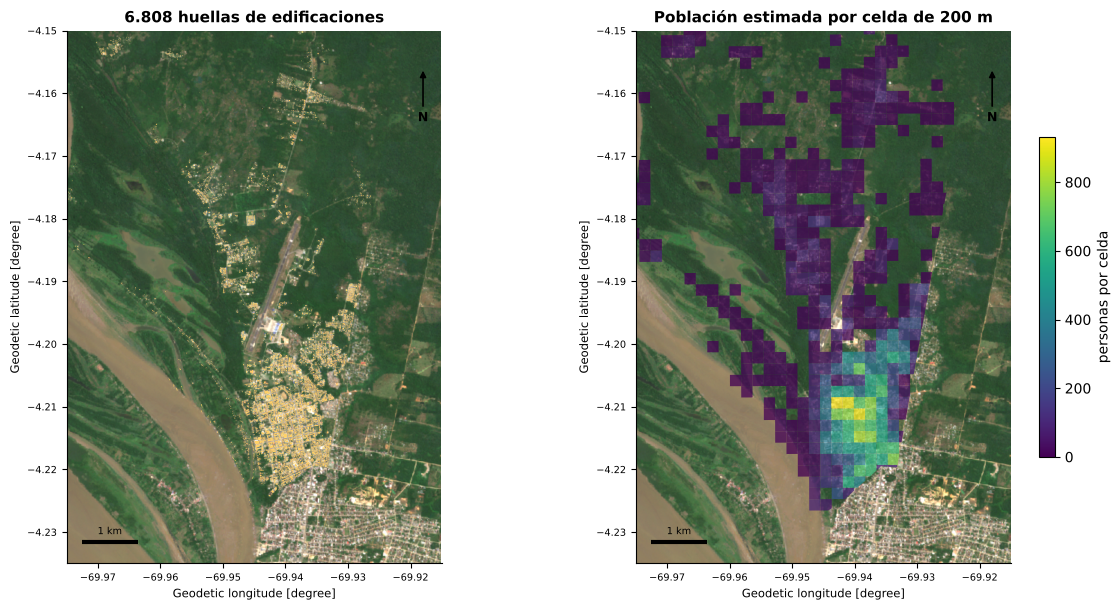

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6.2))
viz.fondo(ax[0])
edif.to_crs(4326).plot(ax=ax[0], color="#ffd166", linewidth=0, zorder=2)
viz.marco(ax[0], titulo=f"{len(edif):,} huellas de edificaciones".replace(",", "."))
viz.mapa_celdas(malla[malla.n_edif > 0], "poblacion", ax=ax[1], cmap="viridis", etiqueta="personas por celda",
                titulo="Población estimada por celda de 200 m")
fig.tight_layout()

In [7]:
viz.pie(viz.nota_fuente("edificaciones", "poblacion"))

*Fuente: Microsoft – Global ML Building Footprints — Huellas derivadas de imágenes (2014–2024), particionadas por quadkey; Kontur (GHSL, Facebook HRSL, Microsoft Buildings, Copernicus) — Kontur Population Colombia 2023-11-01.*

La población se reparte de forma **dasimétrica**: cada hexágono de Kontur entrega sus habitantes a las
edificaciones que contiene, en proporción al área de la huella, y en los hexágonos de la frontera solo se
conserva la fracción que cae en Colombia. El resultado es una estimación para mapear dónde se concentra la
gente, no un conteo censal; el valor oficial de referencia es el del DANE (CNPV 2018 y sus proyecciones).

In [8]:
dist = edif["area_m2"].describe(percentiles=[0.25, 0.5, 0.75, 0.95])[["mean", "25%", "50%", "75%", "95%", "max"]]
display(dist.rename({"mean": "media", "50%": "mediana"}).round(0).to_frame("área de huella (m²)").T)

,media,25%,mediana,75%,95%,max
área de huella (m²),187.00,61.00,109.00,203.00,590.00,"5,570.00"


## 3. Relieve y coberturas

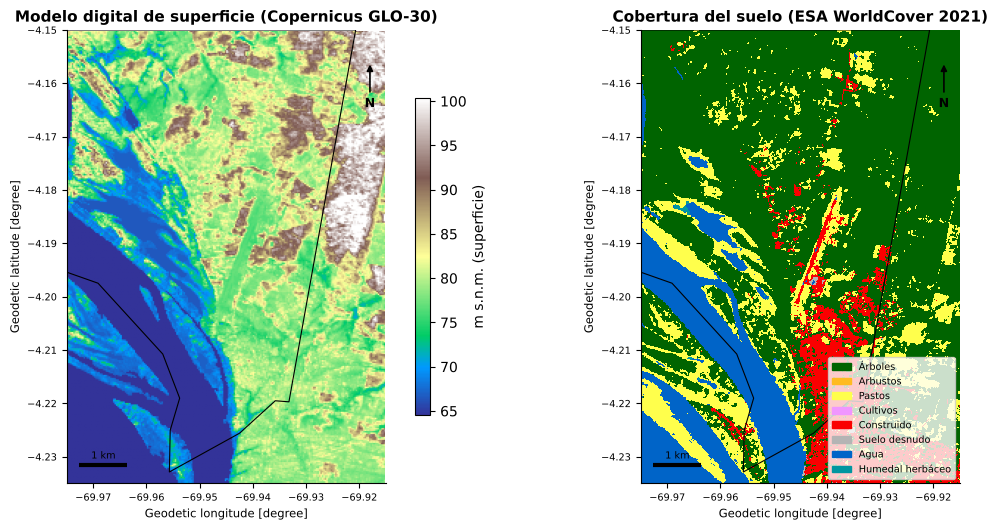

In [9]:
dem = fuentes.raster_estatico("cop-dem-glo-30", "data")
wc = fuentes.raster_estatico("esa-worldcover", "map", clave_bbox="bbox_urbano", resolucion=0.0000898)
fig, ax = plt.subplots(1, 2, figsize=(12, 5.4))
d = dem.sel(x=slice(*fuentes.bbox("bbox_urbano")[0::2]), y=slice(fuentes.bbox("bbox_urbano")[3], fuentes.bbox("bbox_urbano")[1]))
im = ax[0].imshow(d.values, extent=(float(d.x.min()), float(d.x.max()), float(d.y.min()), float(d.y.max())), cmap="terrain",
                  vmin=np.nanpercentile(d, 1), vmax=np.nanpercentile(d, 99))
fig.colorbar(im, ax=ax[0], shrink=0.7, label="m s.n.m. (superficie)")
urbana.to_crs(4326).boundary.plot(ax=ax[0], color="k", lw=0.8)
viz.marco(ax[0], titulo="Modelo digital de superficie (Copernicus GLO-30)")
clases = {10: ("Árboles", "#006400"), 20: ("Arbustos", "#ffbb22"), 30: ("Pastos", "#ffff4c"), 40: ("Cultivos", "#f096ff"),
          50: ("Construido", "#fa0000"), 60: ("Suelo desnudo", "#b4b4b4"), 80: ("Agua", "#0064c8"), 90: ("Humedal herbáceo", "#0096a0")}
from matplotlib.colors import ListedColormap, BoundaryNorm
cods = sorted(clases)
cmap = ListedColormap([clases[k][1] for k in cods])
norm = BoundaryNorm([k - 5 for k in cods] + [cods[-1] + 5], cmap.N)
ax[1].imshow(wc.values, extent=(float(wc.x.min()), float(wc.x.max()), float(wc.y.min()), float(wc.y.max())), cmap=cmap, norm=norm,
             interpolation="nearest")
from matplotlib.patches import Patch
ax[1].legend(handles=[Patch(color=clases[k][1], label=clases[k][0]) for k in cods if (wc.values == k).any()],
             loc="lower right", fontsize=7, frameon=True)
urbana.to_crs(4326).boundary.plot(ax=ax[1], color="k", lw=0.8)
viz.marco(ax[1], titulo="Cobertura del suelo (ESA WorldCover 2021)")
fig.tight_layout()

In [10]:
viz.pie(viz.nota_fuente("elevacion", "cobertura_suelo"))

*Fuente: Copernicus DEM GLO-30 — DSM 30 m (TanDEM-X 2011–2015); ESA WorldCover — WorldCover 10 m 2021 v200.*

In [11]:
dentro = wc.rio.clip(urbana.to_crs(4326).geometry, drop=False)
v = dentro.values[np.isfinite(dentro.values) & (dentro.values > 0)]
fr = pd.Series(v).map({k: n for k, (n, _) in clases.items()}).value_counts(normalize=True).mul(100).round(1)
display(fr.to_frame("% del área urbana de análisis"))

,% del área urbana de análisis
Árboles,69.30
Pastos,13.20
Agua,9.70
Construido,7.50
Humedal herbáceo,0.10
Suelo desnudo,0.10
Arbustos,0.00
Cultivos,0.00


**Lectura.** El modelo de superficie de 30 m (radar TanDEM-X) incluye el dosel y los techos, de modo que en
zonas arboladas sobreestima la altura del suelo; aun así distingue la **terraza alta** donde está el centro de
Leticia de las **zonas bajas** de quebradas (Yahuarcaca, San Antonio) y de la orilla. El área urbana de
análisis conserva una proporción alta de árboles: la ciudad crece sobre bosque, lo que importa para el calor
([3.4](../03_analisis/34_calor/index.md)) y para la interfaz con incendios ([3.5](../03_analisis/35_incendios/index.md)).

## 4. Infraestructura crítica de referencia

,nombre,lat,lon
0,Hospital San Rafael,-4.21,-69.94
1,Aeropuerto Vásquez Cobo,-4.19,-69.94
2,Muelle de Leticia,-4.22,-69.95
3,Malecón,-4.22,-69.94
4,Parque Santander,-4.21,-69.94


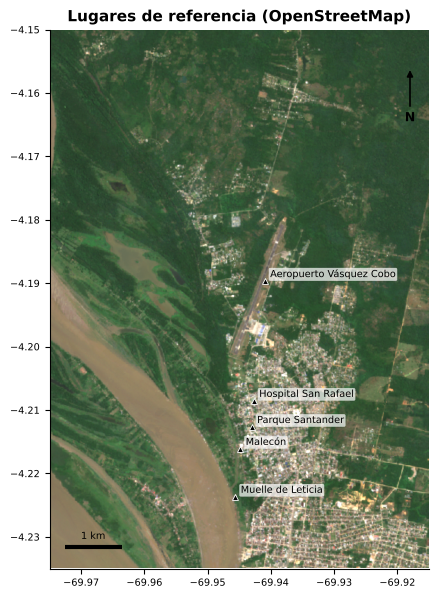

In [12]:
lugares = intentar(fuentes.lugares_clave, mensaje="Nominatim no respondió")
if lugares is not None:
    fig, ax = plt.subplots(figsize=(6.4, 7))
    viz.fondo(ax)
    viz.leyenda_puntos(ax, lugares)
    viz.marco(ax, titulo="Lugares de referencia (OpenStreetMap)")
    display(lugares[["nombre", "lat", "lon"]].round(4))

In [13]:
viz.pie(viz.nota_fuente("lugares_clave"))

*Fuente: OpenStreetMap (Nominatim) — Geocodificación de lugares con nombre.*

:::{seealso}
Las capas creadas aquí (`malla_exposicion.parquet`, `edificaciones_urbanas.parquet`, `s2_rgb_bbox_regional.tif`)
son el insumo de exposición de todos los cuadernos *c. Riesgo* de la Sección 3.
:::